In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd 
import seaborn as sns 

from scipy.stats import norm

df = pd.read_csv('ames_prices.csv')
df.head()

,Order,PID,area,price,MS.SubClass,MS.Zoning,Lot.Frontage,Lot.Area,Street,Alley,...,Screen.Porch,Pool.Area,Pool.QC,Fence,Misc.Feature,Misc.Val,Mo.Sold,Yr.Sold,Sale.Type,Sale.Condition
0,1,526301100,1656,215000,20,RL,141.0,31770,Pave,NaN,...,0,0,NaN,NaN,NaN,0,5,2010,WD,Normal
1,2,526350040,896,105000,20,RH,80.0,11622,Pave,NaN,...,120,0,NaN,MnPrv,NaN,0,6,2010,WD,Normal
2,3,526351010,1329,172000,20,RL,81.0,14267,Pave,NaN,...,0,0,NaN,NaN,Gar2,12500,6,2010,WD,Normal
3,4,526353030,2110,244000,20,RL,93.0,11160,Pave,NaN,...,0,0,NaN,NaN,NaN,0,4,2010,WD,Normal
4,5,527105010,1629,189900,60,RL,74.0,13830,Pave,NaN,...,0,0,NaN,MnPrv,NaN,0,3,2010,WD,Normal


## PROBLEM 7

**Part A**

In [2]:
df['central_air'] = (df['Central.Air'] == 'Y').astype(int)
y = df['central_air']
beta_hat = y.mean()
print(f'Proportion of homes with central air: {beta_hat:.4f}')

Proportion of homes with central air: 0.9331


**Part B**

In [3]:
seed = 42                     
np.random.seed(seed)           
R = 2_000                      
results = []
for t in range(R):
    idx = np.random.randint( 0 , len(df), len(df))
    beta_hat_t = y.iloc[idx].mean()   
    results.append(beta_hat_t)
results = np.array(results)
print(f'Seed: {seed}, Bootstrap replications: {R}')

Seed: 42, Bootstrap replications: 2000


**Part C & D**

Bootstrap standard error for central_air: 0.0047
90% Confidence Interval for central_air: [0.9254, 0.9408]
95% Confidence Interval for central_air: [0.9240, 0.9423]
99% Confidence Interval for central_air: [0.9211, 0.9451]


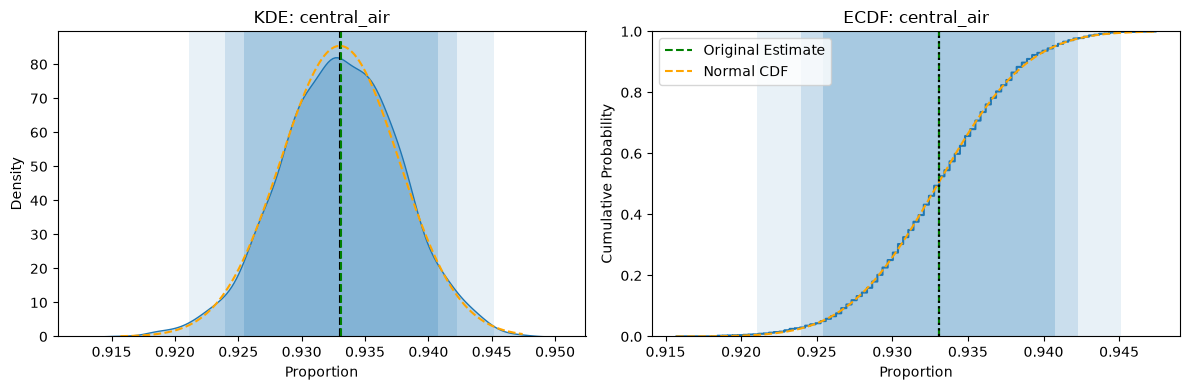

In [4]:
var = 'central_air'
sample = results
mean = np.mean(sample)
standard_error = np.std(sample, ddof=1)
print(f'Bootstrap standard error for {var}: {standard_error:.4f}')
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

# KDE
sns.kdeplot(sample, fill=True, ax=ax[0])
ax[0].axvline(mean, color='black', linestyle='--')
ax[0].set_title(f'KDE: {var}')
ax[0].set_xlabel('Proportion')
ax[0].set_ylabel('Density')
ax[0].axvline(beta_hat, color='green', linestyle='--',
    label='Original Estimate')
x_grid = np.linspace(sample.min(), sample.max(), 500)
ax[0].plot(
    x_grid,
    norm.pdf(x_grid, loc=mean, scale=standard_error),
    color='orange',
    linestyle='--',
    label='Normal PDF'
)

# ECDF
sns.ecdfplot(sample, ax=ax[1])
ax[1].axvline(beta_hat, color='black', linestyle='--')
ax[1].set_title(f'ECDF: {var}')
ax[1].set_xlabel('Proportion')
ax[1].set_ylabel('Cumulative Probability')
ax[1].set_ylim(0, 1)
ax[1].axvline(beta_hat, color='green', linestyle='--',
    label='Original Estimate')
# Fitted normal CDF
x_grid = np.linspace(sample.min(), sample.max(), 500)
ax[1].plot(
    x_grid,
    norm.cdf(x_grid, loc=mean, scale=standard_error),
    color='orange',
    linestyle='--',
    label='Normal CDF'
)
ax[1].axvline(beta_hat, color='black', linestyle=':')
ax[1].set_title(f'ECDF: {var}')
ax[1].set_xlabel('Proportion')
ax[1].set_ylabel('Cumulative Probability')
ax[1].set_ylim(0, 1)
ax[1].legend()

# Normal confidence intervals: original estimate +/- critical value * bootstrap SE
ci90 = [beta_hat - 1.645 * standard_error, beta_hat + 1.645 * standard_error]
ci95 = [beta_hat - 1.960 * standard_error, beta_hat + 1.960 * standard_error]
ci99 = [beta_hat - 2.576 * standard_error, beta_hat + 2.576 * standard_error]

ax[0].axvspan(ci99[0], ci99[1], alpha=0.10, label="99% CI")
ax[0].axvspan(ci95[0], ci95[1], alpha=0.15, label="95% CI")
ax[0].axvspan(ci90[0], ci90[1], alpha=0.20, label="90% CI")
ax[1].axvspan(ci99[0], ci99[1], alpha=0.10, label="99% CI")
ax[1].axvspan(ci95[0], ci95[1], alpha=0.15, label="95% CI")
ax[1].axvspan(ci90[0], ci90[1], alpha=0.20, label="90% CI")

L, U = ci90
print(f'90% Confidence Interval for {var}: [{L:.4f}, {U:.4f}]')
L, U = ci95
print(f'95% Confidence Interval for {var}: [{L:.4f}, {U:.4f}]')
L, U = ci99
print(f'99% Confidence Interval for {var}: [{L:.4f}, {U:.4f}]')

plt.tight_layout()
plt.show()

**Part E**

In [5]:
z = 0.90
for confidence, ci in [(0.90, ci90), (0.95, ci95), (0.99, ci99)]:
    if ci[0] <= z <= ci[1]:
        print(f'{confidence:.0%} CI: {z} is inside the interval, fail to reject H0 at alpha = {1 - confidence:.2f}')
    else:
        print(f'{confidence:.0%} CI: {z} is outside the interval, reject H0 at alpha = {1 - confidence:.2f}')

90% CI: 0.9 is outside the interval, reject H0 at alpha = 0.10
95% CI: 0.9 is outside the interval, reject H0 at alpha = 0.05
99% CI: 0.9 is outside the interval, reject H0 at alpha = 0.01


.90 is outside all three intervals, so you reject H₀: p = .90 at α = .10, .05 and .01. About 93.3% of homes in the sample have central air. With a bootstrap SE of about 0.0047, that 3.3-point gap is too large to be sampling noise, so the true proportion is above 90%.

## PROBLEM 8

In [6]:
x = np.arcsinh( df['area'] )
y = np.arcsinh( df['price'] )           
beta_hat = np.corrcoef(x, y)[0, 1]       
print(f'Pearson correlation between arcsinh(area) and arcsinh(price): {beta_hat:.4f}')

Pearson correlation between arcsinh(area) and arcsinh(price): 0.7232


**Part A**

In [7]:
seed = 42                    
np.random.seed(seed)           
R = 2_000                      
results = []
for t in range(R):
    idx = np.random.randint( 0 , len(df), len(df))
    beta_hat_t = np.corrcoef(x.iloc[idx], y.iloc[idx])[0, 1]  
    results.append(beta_hat_t)
results = np.array(results)
print(f'Seed: {seed}, Bootstrap replications: {R}')

Seed: 42, Bootstrap replications: 2000


**Part B & C**

Bootstrap standard error for correlation: 0.0098
90% Confidence Interval for correlation: [0.7070, 0.7393]
95% Confidence Interval for correlation: [0.7039, 0.7424]
99% Confidence Interval for correlation: [0.6978, 0.7485]


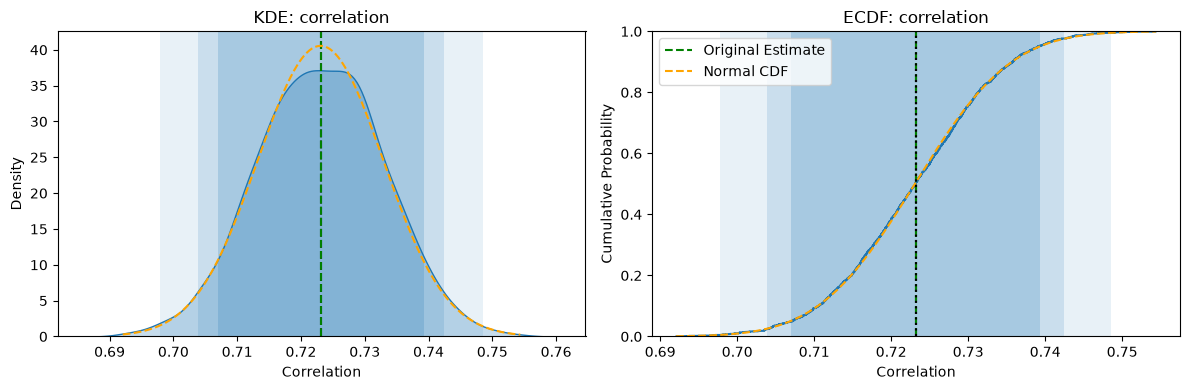

In [8]:
var = 'correlation'
sample = results
mean = np.mean(sample)
standard_error = np.std(sample, ddof=1)
print(f'Bootstrap standard error for {var}: {standard_error:.4f}')
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

# KDE
sns.kdeplot(sample, fill=True, ax=ax[0])
ax[0].axvline(mean, color='black', linestyle='--')
ax[0].set_title(f'KDE: {var}')
ax[0].set_xlabel('Correlation')
ax[0].set_ylabel('Density')
ax[0].axvline(beta_hat, color='green', linestyle='--',
    label='Original Estimate')
x_grid = np.linspace(sample.min(), sample.max(), 500)
ax[0].plot(
    x_grid,
    norm.pdf(x_grid, loc=mean, scale=standard_error),
    color='orange',
    linestyle='--',
    label='Normal PDF'
)

# ECDF
sns.ecdfplot(sample, ax=ax[1])
ax[1].axvline(beta_hat, color='black', linestyle='--')
ax[1].set_title(f'ECDF: {var}')
ax[1].set_xlabel('Correlation')
ax[1].set_ylabel('Cumulative Probability')
ax[1].set_ylim(0, 1)
ax[1].axvline(beta_hat, color='green', linestyle='--',
    label='Original Estimate')
# Fitted normal CDF
x_grid = np.linspace(sample.min(), sample.max(), 500)
ax[1].plot(
    x_grid,
    norm.cdf(x_grid, loc=mean, scale=standard_error),
    color='orange',
    linestyle='--',
    label='Normal CDF'
)
ax[1].axvline(beta_hat, color='black', linestyle=':')
ax[1].set_title(f'ECDF: {var}')
ax[1].set_xlabel('Correlation')
ax[1].set_ylabel('Cumulative Probability')
ax[1].set_ylim(0, 1)
ax[1].legend()

# Centered-Normal confidence intervals: original estimate +/- critical value * bootstrap SE
ci90 = [beta_hat - 1.645 * standard_error, beta_hat + 1.645 * standard_error]
ci95 = [beta_hat - 1.960 * standard_error, beta_hat + 1.960 * standard_error]
ci99 = [beta_hat - 2.576 * standard_error, beta_hat + 2.576 * standard_error]

ax[0].axvspan(ci99[0], ci99[1], alpha=0.10, label="99% CI")
ax[0].axvspan(ci95[0], ci95[1], alpha=0.15, label="95% CI")
ax[0].axvspan(ci90[0], ci90[1], alpha=0.20, label="90% CI")
ax[1].axvspan(ci99[0], ci99[1], alpha=0.10, label="99% CI")
ax[1].axvspan(ci95[0], ci95[1], alpha=0.15, label="95% CI")
ax[1].axvspan(ci90[0], ci90[1], alpha=0.20, label="90% CI")

L, U = ci90
print(f'90% Confidence Interval for {var}: [{L:.4f}, {U:.4f}]')
L, U = ci95
print(f'95% Confidence Interval for {var}: [{L:.4f}, {U:.4f}]')
L, U = ci99
print(f'99% Confidence Interval for {var}: [{L:.4f}, {U:.4f}]')

plt.tight_layout()
plt.show()

**Part D**

In [9]:
z = 0
for confidence, ci in [(0.90, ci90), (0.95, ci95), (0.99, ci99)]:
    if ci[0] <= z <= ci[1]:
        print(f'{confidence:.0%} CI: {z} is inside the interval, fail to reject H0 at alpha = {1 - confidence:.2f}')
    else:
        print(f'{confidence:.0%} CI: {z} is outside the interval, reject H0 at alpha = {1 - confidence:.2f}')

90% CI: 0 is outside the interval, reject H0 at alpha = 0.10
95% CI: 0 is outside the interval, reject H0 at alpha = 0.05
99% CI: 0 is outside the interval, reject H0 at alpha = 0.01


0 is outside all three intervals, so we reject H₀: ρ = 0 at α = .10, .05 and .01. The correlation of 0.72 shows a strong positive association between arcsinh(area) and arcsinh(price): larger homes tend to sell for higher prices. This is only an association. It does not show that adding square footage causes a higher price, since bigger homes also tend to differ in quality, location and age.

**Part E**

area and price must remain paired during resampling because correlation measures how area and price vary together within each house. If area and price are sampled separately, one house’s area would match with another house’s price, which destroys the relationship that we are trying to measure. The bootstrap correlations would then cluster around 0 instead of 0.72. Using one idx for both x and y keeps each house’s area and price together as a pair.

## Problem 9

In [10]:
df = pd.read_csv('metabric.csv')
df.head()

,Age at Diagnosis,Type of Breast Surgery,Cancer Type,Chemotherapy,Hormone Therapy,Lymph nodes examined positive,Mutation Count,Nottingham prognostic index,Overall Survival (Months),Overall Survival Status,Radio Therapy,TMB (nonsynonymous),Tumor Size,Tumor Stage
0,43.19,BREAST CONSERVING,Breast Cancer,NO,YES,0.0,2.0,4.020,84.633333,0:LIVING,YES,2.615035,10.0,1.0
1,48.87,MASTECTOMY,Breast Cancer,YES,YES,1.0,2.0,4.030,163.700000,1:DECEASED,NO,2.615035,15.0,2.0
2,47.68,MASTECTOMY,Breast Cancer,YES,YES,3.0,1.0,4.050,164.933333,0:LIVING,YES,1.307518,25.0,2.0
3,76.97,MASTECTOMY,Breast Cancer,YES,YES,8.0,2.0,6.080,41.366667,1:DECEASED,YES,2.615035,40.0,2.0
4,78.77,MASTECTOMY,Breast Cancer,NO,YES,0.0,4.0,4.062,7.800000,1:DECEASED,YES,5.230071,31.0,4.0


In [11]:
y = df['Overall Survival (Months)'].dropna()      
beta_hat = y.mean()                               
print(f'Number of patients with recorded survival time: {len(y)}')
print(f'Mean Overall Survival: {beta_hat:.4f} months ({beta_hat / 12:.4f} years)')

Number of patients with recorded survival time: 1343
Mean Overall Survival: 129.0943 months (10.7579 years)


**Part A**

In [12]:
seed = 42
np.random.seed(seed)
R = 2_000
results = []
for t in range(R):
    idx = np.random.randint( 0 , len(y), len(y))
    beta_hat_t = y.iloc[idx].mean()
    results.append(beta_hat_t)
results = np.array(results)
print(f'Seed: {seed}, Bootstrap replications: {R}')

Seed: 42, Bootstrap replications: 2000


**Part B & C**

Bootstrap standard error for Overall Survival (Months): 2.1300
90% Confidence Interval for Overall Survival (Months): [125.5904, 132.5982] months, [10.4659, 11.0498] years
95% Confidence Interval for Overall Survival (Months): [124.9195, 133.2691] months, [10.4100, 11.1058] years
99% Confidence Interval for Overall Survival (Months): [123.6074, 134.5812] months, [10.3006, 11.2151] years


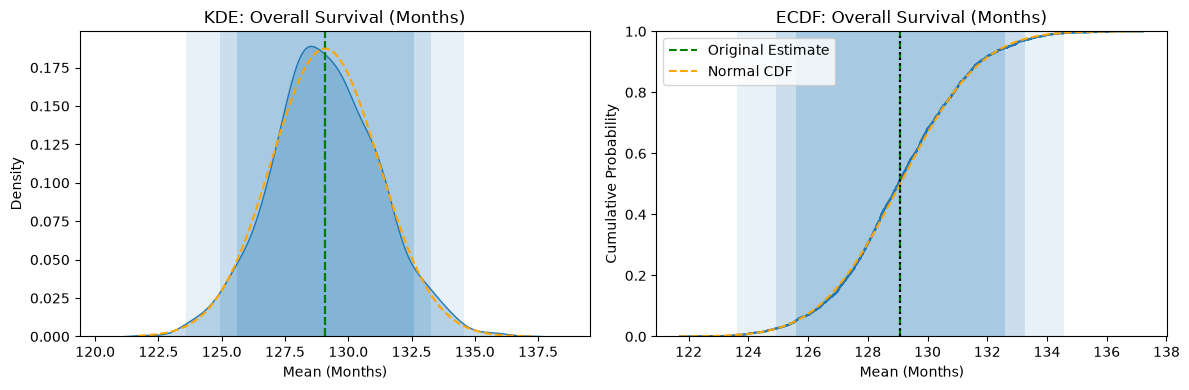

In [13]:
var = 'Overall Survival (Months)'
sample = results
mean = np.mean(sample)
standard_error = np.std(sample, ddof=1)
print(f'Bootstrap standard error for {var}: {standard_error:.4f}')
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

# KDE
sns.kdeplot(sample, fill=True, ax=ax[0])
ax[0].axvline(mean, color='black', linestyle='--')
ax[0].set_title(f'KDE: {var}')
ax[0].set_xlabel('Mean (Months)')
ax[0].set_ylabel('Density')
ax[0].axvline(beta_hat, color='green', linestyle='--',
    label='Original Estimate')
x_grid = np.linspace(sample.min(), sample.max(), 500)
ax[0].plot(
    x_grid,
    norm.pdf(x_grid, loc=mean, scale=standard_error),
    color='orange',
    linestyle='--',
    label='Normal PDF'
)

# ECDF
sns.ecdfplot(sample, ax=ax[1])
ax[1].axvline(beta_hat, color='black', linestyle='--')
ax[1].set_title(f'ECDF: {var}')
ax[1].set_xlabel('Mean (Months)')
ax[1].set_ylabel('Cumulative Probability')
ax[1].set_ylim(0, 1)
ax[1].axvline(beta_hat, color='green', linestyle='--',
    label='Original Estimate')
# Fitted normal CDF
x_grid = np.linspace(sample.min(), sample.max(), 500)
ax[1].plot(
    x_grid,
    norm.cdf(x_grid, loc=mean, scale=standard_error),
    color='orange',
    linestyle='--',
    label='Normal CDF'
)
ax[1].axvline(beta_hat, color='black', linestyle=':')
ax[1].set_title(f'ECDF: {var}')
ax[1].set_xlabel('Mean (Months)')
ax[1].set_ylabel('Cumulative Probability')
ax[1].set_ylim(0, 1)
ax[1].legend()

# Centered-Normal confidence intervals: original estimate +/- critical value * bootstrap SE
ci90 = [beta_hat - 1.645 * standard_error, beta_hat + 1.645 * standard_error]
ci95 = [beta_hat - 1.960 * standard_error, beta_hat + 1.960 * standard_error]
ci99 = [beta_hat - 2.576 * standard_error, beta_hat + 2.576 * standard_error]

ax[0].axvspan(ci99[0], ci99[1], alpha=0.10, label="99% CI")
ax[0].axvspan(ci95[0], ci95[1], alpha=0.15, label="95% CI")
ax[0].axvspan(ci90[0], ci90[1], alpha=0.20, label="90% CI")
ax[1].axvspan(ci99[0], ci99[1], alpha=0.10, label="99% CI")
ax[1].axvspan(ci95[0], ci95[1], alpha=0.15, label="95% CI")
ax[1].axvspan(ci90[0], ci90[1], alpha=0.20, label="90% CI")

# Printed in months and years for part e
L, U = ci90
print(f'90% Confidence Interval for {var}: [{L:.4f}, {U:.4f}] months, [{L/12:.4f}, {U/12:.4f}] years')
L, U = ci95
print(f'95% Confidence Interval for {var}: [{L:.4f}, {U:.4f}] months, [{L/12:.4f}, {U/12:.4f}] years')
L, U = ci99
print(f'99% Confidence Interval for {var}: [{L:.4f}, {U:.4f}] months, [{L/12:.4f}, {U/12:.4f}] years')

plt.tight_layout()
plt.show()

**Part D**

In [14]:
z = 120
for confidence, ci in [(0.90, ci90), (0.95, ci95), (0.99, ci99)]:
    if ci[0] <= z <= ci[1]:
        print(f'{confidence:.0%} CI: {z} is inside the interval, fail to reject H0 at alpha = {1 - confidence:.2f}')
    else:
        print(f'{confidence:.0%} CI: {z} is outside the interval, reject H0 at alpha = {1 - confidence:.2f}')

90% CI: 120 is outside the interval, reject H0 at alpha = 0.10
95% CI: 120 is outside the interval, reject H0 at alpha = 0.05
99% CI: 120 is outside the interval, reject H0 at alpha = 0.01


**Part E**

The average recorded survival time is about 129.1 months, or about 10.8 years. At 95% confidence, thethe true mean recorded survival time is between 124.9 and 133.3 months (10.4 to 11.1 years). The 90% interval is 125.6 to 132.6 months (10.5 to 11.0 years), and the 99% interval is 123.6 to 134.6 months (10.3 to 11.2 years). All three are above 120 months (10 years).

These results are not the average lifetime because many patients were still alive at their last follow up. For those patients we only know they lived at least that long and we do now know when they actually died. Counting their follow up time as if it were their death time makes the average lower than the true mean lifetime. So these numbers estimate the average time patients were followed in this study, not how long they actually lived.

## Problem 10

In [15]:
df = pd.read_csv('nhanes_data_17_18.csv', low_memory=False)
df.head()

,SEQN,GeneralHealthCondition,EverBreastfedOrFedBreastmilk,AgeStoppedBreastfeedingdays,AgeFirstFedFormuladays,AgeStoppedReceivingFormuladays,AgeStartedOtherFoodbeverage,AgeFirstFedMilkdays,TypeOfMilkFirstFedWholeMilk,TypeOfMilkFirstFed2Milk,...,DaysSmokedCigsDuringPast30Days,AvgCigarettesdayDuringPast30Days,TriedToQuitSmoking,TimesStoppedSmokingCigarettes,HowLongWereYouAbleToStopSmoking,UnitOfMeasureDayweekmonthyear_2_SMQ,CurrentSelfreportedHeightInches,CurrentSelfreportedWeightPounds,TriedToLoseWeightInPastYear,TimesLost10LbsOrMoreToLoseWeight
0,93703.0,NaN,1.0,273.0,1.0,365.0,152.0,365.0,Whole or regular milk,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,93704.0,NaN,1.0,60.0,3.0,365.0,126.0,365.0,Whole or regular milk,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,93705.0,Good,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,63.0,165.0,0.0,11 times or more
3,93706.0,Very good,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,68.0,145.0,0.0,Never
4,93707.0,Good,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [16]:
rdf = df.loc[ df['AgeInYearsAtScreening'] >= 18, ['AgeInYearsAtScreening', 'SleepHoursWeekdaysOrWorkdays'] ].dropna()
y = rdf['SleepHoursWeekdaysOrWorkdays']
beta_hat = y.mean()                              
print(f'Number of adults with observed weekday sleep: {len(y)}')
print(f'Mean weekday sleep: {beta_hat:.4f} hours')

Number of adults with observed weekday sleep: 5489
Mean weekday sleep: 7.6212 hours


**Part A**

In [17]:
seed = 42                     
np.random.seed(seed)          
R = 2_000                     
results = []
for t in range(R):
    idx = np.random.randint( 0 , len(y), len(y))
    beta_hat_t = y.iloc[idx].mean()    
    results.append(beta_hat_t)
results = np.array(results)
print(f'Seed: {seed}, Bootstrap replications: {R}')

Seed: 42, Bootstrap replications: 2000


**Part B & C**

Bootstrap standard error for SleepHoursWeekdaysOrWorkdays: 0.0229
90% Confidence Interval for SleepHoursWeekdaysOrWorkdays: [7.5836, 7.6589] hours
95% Confidence Interval for SleepHoursWeekdaysOrWorkdays: [7.5764, 7.6661] hours
99% Confidence Interval for SleepHoursWeekdaysOrWorkdays: [7.5623, 7.6802] hours


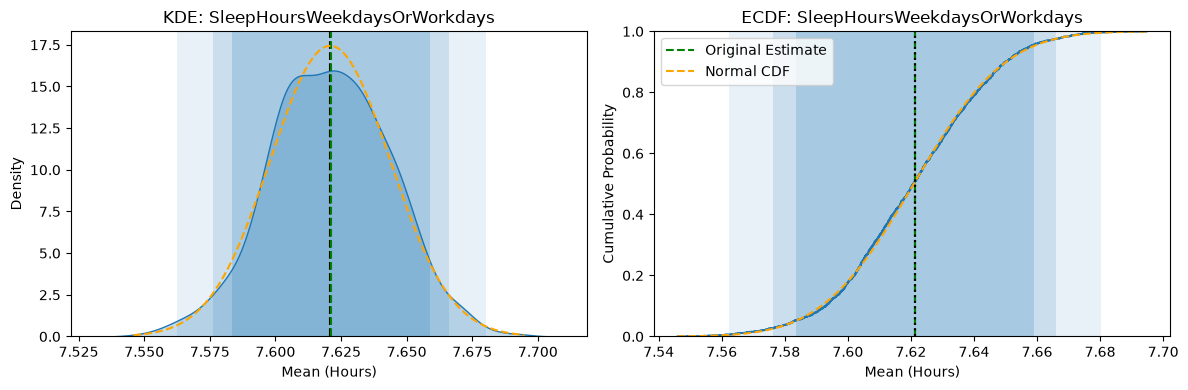

In [18]:
var = 'SleepHoursWeekdaysOrWorkdays'
sample = results
mean = np.mean(sample)
standard_error = np.std(sample, ddof=1)
print(f'Bootstrap standard error for {var}: {standard_error:.4f}')
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

# KDE
sns.kdeplot(sample, fill=True, ax=ax[0])
ax[0].axvline(mean, color='black', linestyle='--')
ax[0].set_title(f'KDE: {var}')
ax[0].set_xlabel('Mean (Hours)')
ax[0].set_ylabel('Density')
ax[0].axvline(beta_hat, color='green', linestyle='--',
    label='Original Estimate')
x_grid = np.linspace(sample.min(), sample.max(), 500)
ax[0].plot(
    x_grid,
    norm.pdf(x_grid, loc=mean, scale=standard_error),
    color='orange',
    linestyle='--',
    label='Normal PDF'
)

# ECDF
sns.ecdfplot(sample, ax=ax[1])
ax[1].axvline(beta_hat, color='black', linestyle='--')
ax[1].set_title(f'ECDF: {var}')
ax[1].set_xlabel('Mean (Hours)')
ax[1].set_ylabel('Cumulative Probability')
ax[1].set_ylim(0, 1)
ax[1].axvline(beta_hat, color='green', linestyle='--',
    label='Original Estimate')
# Fitted normal CDF
x_grid = np.linspace(sample.min(), sample.max(), 500)
ax[1].plot(
    x_grid,
    norm.cdf(x_grid, loc=mean, scale=standard_error),
    color='orange',
    linestyle='--',
    label='Normal CDF'
)
ax[1].axvline(beta_hat, color='black', linestyle=':')
ax[1].set_title(f'ECDF: {var}')
ax[1].set_xlabel('Mean (Hours)')
ax[1].set_ylabel('Cumulative Probability')
ax[1].set_ylim(0, 1)
ax[1].legend()

# Centered-Normal confidence intervals: original estimate +/- critical value * bootstrap SE
ci90 = [beta_hat - 1.645 * standard_error, beta_hat + 1.645 * standard_error]
ci95 = [beta_hat - 1.960 * standard_error, beta_hat + 1.960 * standard_error]
ci99 = [beta_hat - 2.576 * standard_error, beta_hat + 2.576 * standard_error]

ax[0].axvspan(ci99[0], ci99[1], alpha=0.10, label="99% CI")
ax[0].axvspan(ci95[0], ci95[1], alpha=0.15, label="95% CI")
ax[0].axvspan(ci90[0], ci90[1], alpha=0.20, label="90% CI")
ax[1].axvspan(ci99[0], ci99[1], alpha=0.10, label="99% CI")
ax[1].axvspan(ci95[0], ci95[1], alpha=0.15, label="95% CI")
ax[1].axvspan(ci90[0], ci90[1], alpha=0.20, label="90% CI")

L, U = ci90
print(f'90% Confidence Interval for {var}: [{L:.4f}, {U:.4f}] hours')
L, U = ci95
print(f'95% Confidence Interval for {var}: [{L:.4f}, {U:.4f}] hours')
L, U = ci99
print(f'99% Confidence Interval for {var}: [{L:.4f}, {U:.4f}] hours')

plt.tight_layout()
plt.show()

**Part D**

In [19]:
z = 8
for confidence, ci in [(0.90, ci90), (0.95, ci95), (0.99, ci99)]:
    if ci[0] <= z <= ci[1]:
        print(f'{confidence:.0%} CI: {z} is inside the interval, fail to reject H0 at alpha = {1 - confidence:.2f}')
    else:
        print(f'{confidence:.0%} CI: {z} is outside the interval, reject H0 at alpha = {1 - confidence:.2f}')

90% CI: 8 is outside the interval, reject H0 at alpha = 0.10
95% CI: 8 is outside the interval, reject H0 at alpha = 0.05
99% CI: 8 is outside the interval, reject H0 at alpha = 0.01


**Part E**

Adults in this sample average about 7.62 hours of sleep on weekdays, which is about 7 hours and 37 minutes. That is about 0.38 hours, or 23 minutes, less than 8 hours. The result is highly statistically significant, but that is mostly because the sample is large. The sample contains about 5,500 people, and the SE is only about 1.4 minutes, so even a small gap from 8 hours is easy to detect. 23 minutes a night is a real but small difference, and the average is still well above 7 hours. So statistical and practical significance do not fully line up here. The data clearly show the mean is below 8 hours, but the shortfall is small. These results describe this sample of respondents, treating each observation as independent and unweighted. Because the survey design is ignored, they are not nationally representative and the intervals are not survey-adjusted.